# When Is an ATP Tennis Upset Really an Upset? Graphs 2 and 4

This notebook builds my two graphs for the project:

- **Graph 2: ATP ranking vs Elo.** How often does the lower-ranked player win when Elo rates him as the stronger player?
- **Graph 4: Giant Killers.** Which players win more upsets than their ranking predicts, and is that explained by ranking changes (comebacks, fast risers) or by surface?

**Definitions used throughout**
- *Upset* = the lower-ranked player (numerically larger ATP rank) wins. Matches with a missing ranking are excluded.
- *Elo* = chronological pre-match rating, built only from earlier matches (FiveThirtyEight tennis method, 2014 used as warm-up).
- Data: Jeff Sackmann's ATP main-tour match files (no Challengers, Futures, qualifying or Davis Cup), 2014-2025.

**How to run:** open this notebook from the project (`tennis_upsets/` or `tennis_upsets/notebooks/`) and run all cells.
It reads files in `data/processed/`, which the pipeline scripts `run_01` to `run_07` create.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

%matplotlib inline

# Works whether the notebook is opened from the project root or from notebooks/
PROJECT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(PROJECT))
from src import config

DATA = PROJECT / "data" / "processed"
FIG = PROJECT / "outputs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
assert (DATA / "atp_model_dataset.csv").exists(), "Run the pipeline scripts run_01 ... run_07 first"
pd.set_option("display.width", 200)

# Style tokens (shared with the other project figures)
BG = "#fcfcfb"
INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS = "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, GREEN = "#2a78d6", "#eb6834", "#1baf7a"

plt.rcParams.update({
    "font.family": ["Helvetica Neue", "Arial", "DejaVu Sans"],
    "figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG,
    "text.color": INK, "axes.labelcolor": INK_2, "xtick.color": MUTED, "ytick.color": INK_2,
    "axes.edgecolor": AXIS, "font.size": 10,
})


def clean_axis(ax, grid="x"):
    # Light gridlines, no box, no tick marks
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.grid(axis=grid, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(length=0, labelsize=9)


print("Project folder:", PROJECT)

Project folder: /Users/katelynsmith/tennis_upsets


---
## Graph 2: ATP ranking vs Elo disagreement

For every match, the ATP ranking names a favorite. Elo gives a second opinion:

- **Elo agrees**: the higher-ranked player also has the higher pre-match Elo.
- **Elo disagrees**: the lower-ranked player has the higher pre-match Elo.

Elo disagrees most often when the ranking gap is small, and small gaps produce more upsets anyway.
So the two groups are compared **within ranking-gap bands** (underdog rank / favorite rank).

In [2]:
RATIO_BINS = [1, 1.5, 2.5, 5, np.inf]
RATIO_LABELS = ["Close\n(under 1.5x)", "Moderate\n(1.5-2.5x)", "Large\n(2.5-5x)", "Huge\n(5x or more)"]
MIN_ELO_MATCHES = 20   # robustness check: Elo is unreliable for players with few rated matches

d = pd.read_csv(DATA / "atp_model_dataset.csv", parse_dates=["tourney_date"], low_memory=False)
print(f"Rows in model dataset: {len(d):,}")
d = d[d["completed"] & d["upset_label_ok"] & (d["season"] >= config.MODEL_FIRST_SEASON)]
print(f"Completed, rank label defined, season >= {config.MODEL_FIRST_SEASON}: {len(d):,}")

ties = (d["elo_diff"] == 0).sum()
d = d[d["elo_diff"] != 0].copy()
print(f"Dropped {ties} exact Elo ties -> {len(d):,} matches")

d["elo_view"] = np.where(d["elo_diff"] > 0, "agrees", "disagrees")   # elo_diff = favorite Elo - underdog Elo
d["rank_ratio"] = d["dog_rank_eff"] / d["fav_rank_eff"]
d["gap_band"] = pd.cut(d["rank_ratio"], RATIO_BINS, labels=RATIO_LABELS, right=False)
d["elo_reliable"] = (d["fav_elo_n"] >= MIN_ELO_MATCHES) & (d["dog_elo_n"] >= MIN_ELO_MATCHES)

Rows in model dataset: 27,058
Completed, rank label defined, season >= 2015: 27,058
Dropped 14 exact Elo ties -> 27,044 matches


### Sanity checks

In [3]:
print("Upset label matches ranks on every row:", (d["upset"] == (d["winner_rank"] > d["loser_rank"])).all())
print("Every match has rank ratio >= 1:", (d["rank_ratio"] >= 1).all())
print("Matches with no gap band (should be 0):", d["gap_band"].isna().sum())
print(f"\nElo disagrees with the ranking in {(d['elo_view'] == 'disagrees').mean():.1%} of matches")
print("\nShare of matches where Elo disagrees, by ranking-gap band:")
print(d.groupby("gap_band", observed=True)["elo_view"].apply(lambda s: (s == "disagrees").mean()).round(3).to_string())
print(f"\nBoth players have >= {MIN_ELO_MATCHES} prior Elo matches in {d['elo_reliable'].mean():.1%} of matches")

Upset label matches ranks on every row: True
Every match has rank ratio >= 1: True
Matches with no gap band (should be 0): 0

Elo disagrees with the ranking in 18.0% of matches

Share of matches where Elo disagrees, by ranking-gap band:
gap_band
Close\n(under 1.5x)     0.396
Moderate\n(1.5-2.5x)    0.212
Large\n(2.5-5x)         0.095
Huge\n(5x or more)      0.035

Both players have >= 20 prior Elo matches in 78.1% of matches


### Upset rates

`upset_rate` is the share of matches won by the lower-ranked player, with a 95% Wilson interval.
`elo_pred_upset_rate` is the average upset probability Elo itself gave those matches (a calibration check).

In [4]:
def wilson_ci(k, n, z=1.96):
    # 95% Wilson interval for a proportion k/n
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half


def summarise(df, by):
    out = df.groupby(by, observed=True).agg(matches=("upset", "size"), upsets=("upset", "sum"),
                                            elo_pred_upset_rate=("elo_prob_dog", "mean")).reset_index()
    out["upset_rate"] = out["upsets"] / out["matches"]
    out["ci_low"], out["ci_high"] = wilson_ci(out["upsets"], out["matches"])
    return out


print("Overall:")
print(summarise(d, ["elo_view"]).round(3).to_string(index=False))
g2 = summarise(d, ["gap_band", "elo_view"])
print("\nBy ranking-gap band:")
print(g2.round(3).to_string(index=False))

Overall:
 elo_view  matches  upsets  elo_pred_upset_rate  upset_rate  ci_low  ci_high
   agrees    22174    7075                0.284       0.319   0.313    0.325
disagrees     4870    2488                0.598       0.511   0.497    0.525

By ranking-gap band:
            gap_band  elo_view  matches  upsets  elo_pred_upset_rate  upset_rate  ci_low  ci_high
 Close\n(under 1.5x)    agrees     3779    1618                0.375       0.428   0.412    0.444
 Close\n(under 1.5x) disagrees     2476    1322                0.601       0.534   0.514    0.554
Moderate\n(1.5-2.5x)    agrees     5659    2274                0.343       0.402   0.389    0.415
Moderate\n(1.5-2.5x) disagrees     1526     762                0.591       0.499   0.474    0.524
     Large\n(2.5-5x)    agrees     5932    1867                0.284       0.315   0.303    0.327
     Large\n(2.5-5x) disagrees      622     304                0.594       0.489   0.450    0.528
  Huge\n(5x or more)    agrees     6804    1316     

In [5]:
print(f"Robustness: only matches where both players have >= {MIN_ELO_MATCHES} prior Elo matches")
print(summarise(d[d["elo_reliable"]], ["gap_band", "elo_view"]).round(3).to_string(index=False))
print("\nBy surface:")
print(summarise(d, ["surface", "elo_view"]).round(3).to_string(index=False))

Robustness: only matches where both players have >= 20 prior Elo matches
            gap_band  elo_view  matches  upsets  elo_pred_upset_rate  upset_rate  ci_low  ci_high
 Close\n(under 1.5x)    agrees     3093    1301                0.381       0.421   0.403    0.438
 Close\n(under 1.5x) disagrees     1977    1046                0.595       0.529   0.507    0.551
Moderate\n(1.5-2.5x)    agrees     4588    1843                0.348       0.402   0.388    0.416
Moderate\n(1.5-2.5x) disagrees     1201     622                0.585       0.518   0.490    0.546
     Large\n(2.5-5x)    agrees     4609    1457                0.286       0.316   0.303    0.330
     Large\n(2.5-5x) disagrees      414     230                0.593       0.556   0.507    0.603
  Huge\n(5x or more)    agrees     5069    1001                0.180       0.197   0.187    0.209
  Huge\n(5x or more) disagrees      168      78                0.638       0.464   0.391    0.540

By surface:
surface  elo_view  matches  upse

### Figure

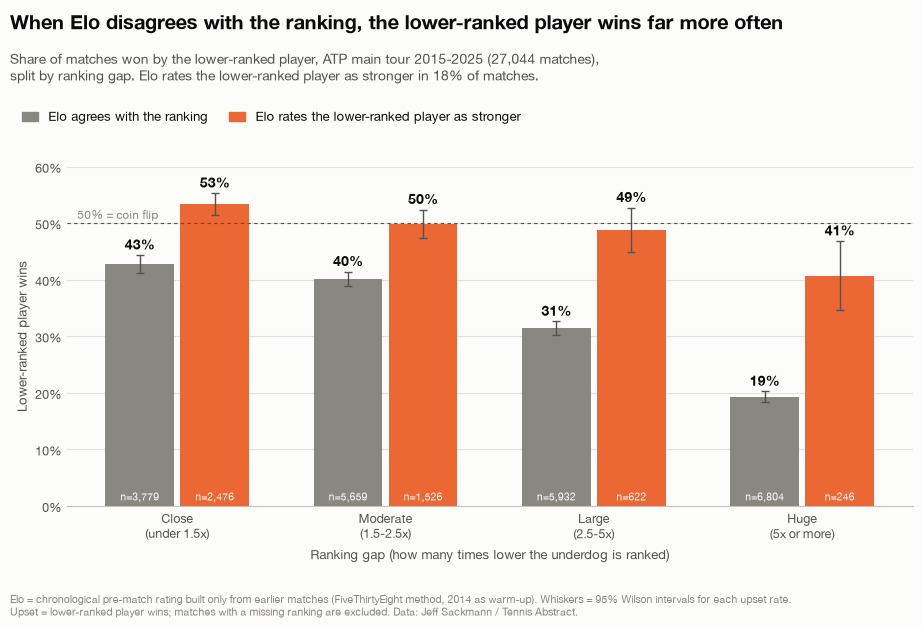

In [6]:
fig, ax = plt.subplots(figsize=(9.5, 6.4))
fig.subplots_adjust(left=0.08, right=0.97, top=0.73, bottom=0.2)
x = np.arange(len(RATIO_LABELS))
width = 0.36
for offset, view, color in ((-width / 2, "agrees", MUTED), (width / 2, "disagrees", ORANGE)):
    t = g2[g2["elo_view"] == view].set_index("gap_band").reindex(RATIO_LABELS)
    rate = 100 * t["upset_rate"]
    ax.bar(x + offset, rate, width=width - 0.03, color=color, linewidth=0)
    ax.errorbar(x + offset, rate, yerr=[rate - 100 * t["ci_low"], 100 * t["ci_high"] - rate],
                fmt="none", ecolor=INK_2, elinewidth=1, capsize=3)
    for xi, r, hi, n in zip(x + offset, rate, 100 * t["ci_high"], t["matches"]):
        ax.annotate(f"{r:.0f}%", xy=(xi, hi), xytext=(0, 4), textcoords="offset points",
                    ha="center", fontsize=10, fontweight="bold", color=INK)
        ax.annotate(f"n={int(n):,}", xy=(xi, 0), xytext=(0, 4), textcoords="offset points",
                    ha="center", fontsize=7.5, color=BG)

ax.axhline(50, color=INK_2, linewidth=0.8, linestyle=(0, (3, 3)))
ax.text(-0.48, 50.8, "50% = coin flip", ha="left", fontsize=8.5, color=MUTED)
ax.set_xticks(x, RATIO_LABELS, fontsize=9.5)
ax.set_ylim(0, 60)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:.0f}%"))
clean_axis(ax, grid="y")
ax.tick_params(axis="x", colors=INK_2)
ax.set_ylabel("Lower-ranked player wins", fontsize=9.5)
ax.set_xlabel("Ranking gap (how many times lower the underdog is ranked)", fontsize=9.5)

fig.text(0.02, 0.945, "When Elo disagrees with the ranking, the lower-ranked player wins far more often",
         fontsize=14.5, fontweight="bold")
fig.text(0.02, 0.865, f"Share of matches won by the lower-ranked player, ATP main tour "
         f"{int(d['season'].min())}-{int(d['season'].max())} ({len(d):,} matches),\nsplit by ranking gap. "
         f"Elo rates the lower-ranked player as stronger in {(d['elo_view'] == 'disagrees').mean():.0%} of matches.",
         fontsize=10, color=INK_2)
fig.legend(handles=[Patch(color=MUTED, label="Elo agrees with the ranking"),
                    Patch(color=ORANGE, label="Elo rates the lower-ranked player as stronger")],
           loc="upper left", bbox_to_anchor=(0.02, 0.84), ncol=2, frameon=False, fontsize=9.5,
           handlelength=1.2, columnspacing=1.6)
fig.text(0.02, 0.025, "Elo = chronological pre-match rating built only from earlier matches "
         "(FiveThirtyEight method, 2014 as warm-up). Whiskers = 95% Wilson intervals for each upset rate.\n"
         "Upset = lower-ranked player wins; matches with a missing ranking are excluded. "
         "Data: Jeff Sackmann / Tennis Abstract.", fontsize=7.6, color=MUTED, va="bottom")
fig.savefig(FIG / "graph2_rank_vs_elo.png", dpi=200)
fig.savefig(FIG / "graph2_rank_vs_elo.svg")
g2.to_csv(DATA / "graph2_chart_data.csv", index=False)
plt.show()

### Graph 2 findings

- Elo rates the lower-ranked player as stronger in **18%** of matches: 40% of close matches but only 3.5% of huge-gap ones.
- In **every** ranking-gap band, the lower-ranked player wins more often when Elo disagrees (close 43% → 53%, moderate 40% → 50%, large 31% → 49%, huge 19% → 41%). None of the intervals overlap.
- The difference **grows with the ranking gap** (+10 to +21 points): the ranking is most misleading where it shows the biggest mismatch.
- When Elo disagrees, the "upset" is close to a **coin flip** (51% overall).
- Elo alone overstates these cases (it predicted about 60%), so the ranking still carries useful information.
- The pattern holds when both players have 20+ rated matches and on all three surfaces (slightly weaker on clay).

---
## Graph 4: Giant Killers

**Giant Killer Score = actual upset wins − expected upset wins**, over every match a player played as the lower-ranked player ("opportunities"), 2016-2025.

- **Expected wins** = sum of `p_log_rank`: the upset probability from a logistic model using the log ranking gap and surface.
  Each season is predicted only from earlier seasons (2014-15 serve as history), then shifted so each season's expected upsets equal its actual upsets.
  These probabilities are built in `run_06_giant_killers.py`.
- **Range** = score ± 1.96 × se, where se² = Σ p(1 − p). This is an *approximate expected-variation range*: it covers match-to-match chance given the probabilities,
  but not uncertainty in the model itself, so it is **not** a full 95% confidence interval.
- **Flags** (from `src/flags.py`, descriptive only, never used in the model):
  - *comeback* = best ranking in the prior 3 years was top-30 and at least 3x better than his current ranking;
  - *riser* = aged 23 or younger and ranked at least 2x better a year later (this uses future rankings);
  - a player is flagged when at least 30% of his underdog matches meet the definition.

In [7]:
pm = pd.read_csv(DATA / "gk_match_predictions.csv", parse_dates=["tourney_date"])
g4 = pd.read_csv(DATA / "graph4_chart_data.csv")
g4["flag"] = g4["flag"].fillna("none")
print(f"Underdog opportunities: {len(pm):,}, seasons {pm['season'].min()}-{pm['season'].max()}")
print(f"Players with >= {config.GK_MIN_OPPORTUNITIES} opportunities: {len(g4)}")

# Recompute every player's score straight from the per-match probabilities and check it matches the chart table
recomputed = pm.groupby("dog_id").agg(opportunities=("upset", "size"), upset_wins=("upset", "sum"),
                                      expected_wins=("p_log_rank", "sum"))
recomputed["se"] = np.sqrt(pm.assign(v=pm["p_log_rank"] * (1 - pm["p_log_rank"])).groupby("dog_id")["v"].sum())
recomputed["gk_score"] = recomputed["upset_wins"] - recomputed["expected_wins"]
chk = g4.set_index("dog_id").join(recomputed.add_suffix("_check"))
for c in ["opportunities", "upset_wins", "expected_wins", "se", "gk_score"]:
    print(f"max |{c} - recomputed|: {(chk[c] - chk[c + '_check']).abs().max():.2e}")

# Ranking on everyone (no minimum) gives the same top 20
no_min_top20 = recomputed.sort_values("gk_score", ascending=False).head(20).index
print("Top 20 identical with no opportunity minimum:",
      set(no_min_top20) == set(g4.sort_values("gk_score", ascending=False).head(20)["dog_id"]))

Underdog opportunities: 24,540, seasons 2016-2025
Players with >= 30 opportunities: 257
max |opportunities - recomputed|: 0.00e+00
max |upset_wins - recomputed|: 0.00e+00
max |expected_wins - recomputed|: 1.42e-14
max |se - recomputed|: 8.88e-16
max |gk_score - recomputed|: 1.42e-14
Top 20 identical with no opportunity minimum: True


In [8]:
g4 = g4.sort_values("gk_score", ascending=False)
g4["range_low"] = g4["gk_score"] - 1.96 * g4["se"]
g4["range_high"] = g4["gk_score"] + 1.96 * g4["se"]
top = g4.head(20)
print(top[["player", "flag", "opportunities", "upset_wins", "expected_wins", "gk_score",
           "range_low", "range_high", "z"]].round(2).to_string(index=False))
print("\nFlags among the top 20:", top["flag"].value_counts().to_dict())
print(f"Players with z > 2: {(g4['z'] > 2).sum()} of {len(g4)} (about {0.0228 * len(g4):.0f} expected by chance)")

               player     flag  opportunities  upset_wins  expected_wins  gk_score  range_low  range_high    z
Juan Martin del Potro comeback             72          43          17.85     25.15      18.30       32.00 7.20
         Nick Kyrgios comeback            100          57          32.40     24.60      15.75       33.45 5.45
      Jenson Brooksby     none             78          42          25.02     16.98       9.21       24.75 4.28
        Stan Wawrinka comeback            138          62          45.24     16.76       6.32       27.20 3.15
          Jack Draper    riser             77          44          27.48     16.52       8.53       24.52 4.05
      Sebastian Korda     none            115          59          43.62     15.38       5.40       25.36 3.02
   Thanasi Kokkinakis     none             97          45          31.31     13.69       4.98       22.40 3.08
       Carlos Alcaraz    riser             53          33          19.35     13.65       6.94       20.37 3.99
 

### Figure

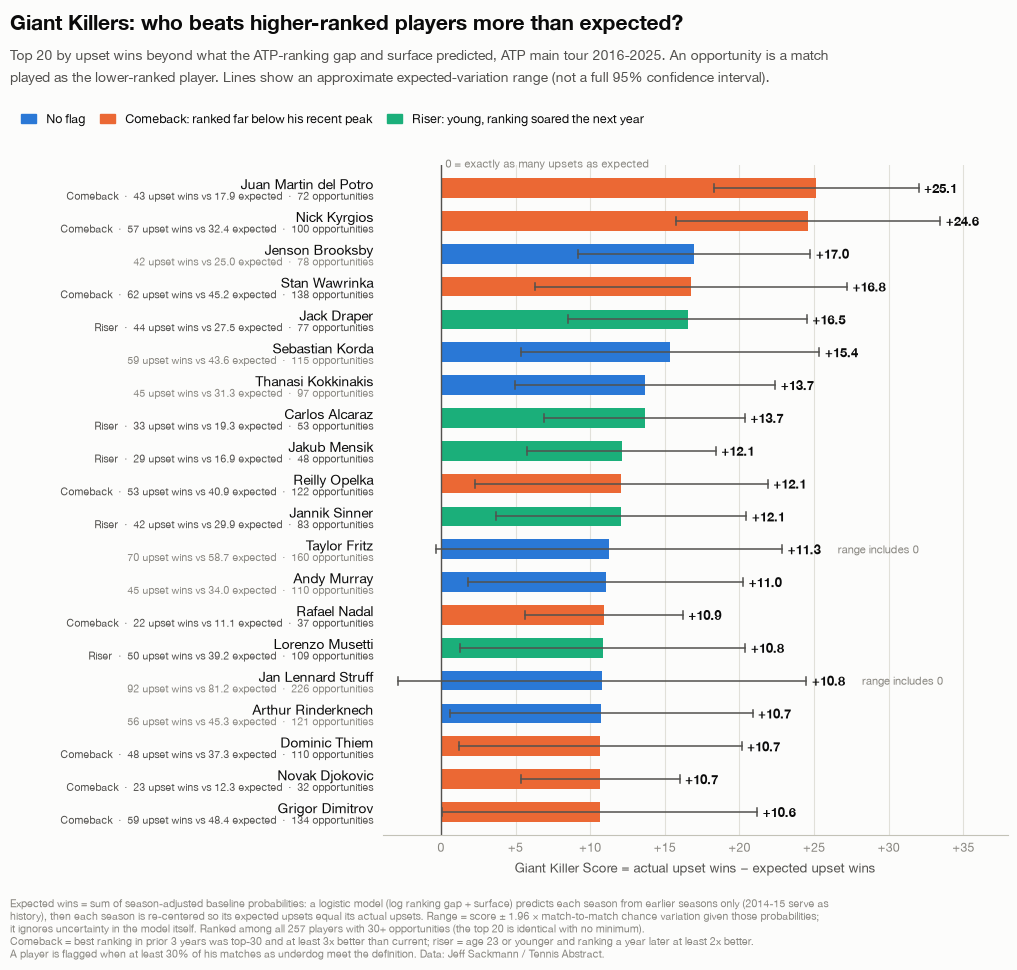

In [9]:
FLAG_STYLE = {"none": (BLUE, None), "comeback": (ORANGE, "comeback"), "riser": (GREEN, "riser")}
t = top.iloc[::-1]   # largest at the top
fig, ax = plt.subplots(figsize=(10.5, 10))
fig.subplots_adjust(left=0.375, right=0.97, top=0.82, bottom=0.15)
ys = np.arange(len(t))
for yv, (_, r) in zip(ys, t.iterrows()):
    color, tag = FLAG_STYLE[r["flag"]]
    lo, hi = r["range_low"], r["range_high"]
    ax.barh(yv, r["gk_score"], height=0.6, color=color, linewidth=0)
    # Expected-variation range: thin line with short end caps
    ax.plot([lo, hi], [yv, yv], color=INK_2, linewidth=1.1, zorder=3)
    ax.plot([lo, lo], [yv - 0.12, yv + 0.12], color=INK_2, linewidth=1.1, zorder=3)
    ax.plot([hi, hi], [yv - 0.12, yv + 0.12], color=INK_2, linewidth=1.1, zorder=3)
    ax.annotate(f"{r['gk_score']:+.1f}", xy=(hi, yv), xytext=(4, 0), textcoords="offset points",
                va="center", fontsize=9.5, fontweight="bold")
    if lo <= 0:
        ax.annotate("range includes 0", xy=(hi, yv), xytext=(40, 0), textcoords="offset points",
                    va="center", fontsize=8, color=MUTED)
    ax.text(-0.015, yv + 0.12, r["player"], transform=ax.get_yaxis_transform(), ha="right", va="center", fontsize=10)
    detail = (f"{int(r['upset_wins'])} upset wins vs {r['expected_wins']:.1f} expected"
              f"  ·  {int(r['opportunities'])} opportunities")
    if tag:
        detail = f"{tag.capitalize()}  ·  " + detail
    ax.text(-0.015, yv - 0.24, detail, transform=ax.get_yaxis_transform(), ha="right", va="center",
            fontsize=7.6, color=INK_2 if tag else MUTED)

ax.set_yticks([])
ax.axvline(0, color=INK_2, linewidth=1)
ax.set_xlim(min(0, t["range_low"].min()) - 1, t["range_high"].max() + 4.5)
ax.set_ylim(-0.7, len(t) - 0.3)
clean_axis(ax)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:+.0f}" if v else "0"))
ax.text(0.3, len(t) - 0.45, "0 = exactly as many upsets as expected", fontsize=8, color=MUTED, va="bottom")
ax.set_xlabel("Giant Killer Score = actual upset wins − expected upset wins", fontsize=9.5)

fig.text(0.02, 0.955, "Giant Killers: who beats higher-ranked players more than expected?", fontsize=15, fontweight="bold")
fig.text(0.02, 0.925, "Top 20 by upset wins beyond what the ATP-ranking gap and surface predicted, "
         "ATP main tour 2016-2025. An opportunity is a match", fontsize=10, color=INK_2)
fig.text(0.02, 0.903, "played as the lower-ranked player. Lines show an approximate expected-variation range "
         "(not a full 95% confidence interval).", fontsize=10, color=INK_2)
fig.legend(handles=[Patch(color=BLUE, label="No flag"),
                    Patch(color=ORANGE, label="Comeback: ranked far below his recent peak"),
                    Patch(color=GREEN, label="Riser: young, ranking soared the next year")],
           loc="upper left", bbox_to_anchor=(0.02, 0.885), ncol=3, frameon=False, fontsize=9,
           handlelength=1.2, columnspacing=1.2)
fig.text(0.02, 0.025, "Expected wins = sum of season-adjusted baseline probabilities: a logistic model (log "
         "ranking gap + surface) predicts each season from earlier seasons only (2014-15 serve as\nhistory), "
         "then each season is re-centered so its expected upsets equal its actual upsets. Range = score ± 1.96 × "
         "match-to-match chance variation given those probabilities;\nit ignores uncertainty in the model "
         f"itself. Ranked among all {len(g4)} players with {config.GK_MIN_OPPORTUNITIES}+ opportunities "
         "(the top 20 is identical with no minimum).\nComeback = best ranking in prior 3 years was top-30 and at "
         "least 3x better than current; riser = age 23 or younger and ranking a year later at least 2x better.\n"
         f"A player is flagged when at least {config.FLAG_PLAYER_SHARE:.0%} of his matches as underdog meet the "
         "definition. Data: Jeff Sackmann / Tennis Abstract.", fontsize=7.6, color=MUTED, va="bottom")
fig.savefig(FIG / "graph4_giant_killers.png", dpi=200)
fig.savefig(FIG / "graph4_giant_killers.svg")
plt.show()

### Graph 4 findings

- Del Potro (+25.1: 43 upset wins vs 17.9 expected) and Kyrgios (+24.6) lead, followed by Brooksby, Wawrinka and Draper.
- **13 of the top 20 are flagged**: 8 comebacks (del Potro, Kyrgios, Wawrinka, Opelka, Nadal, Thiem, Djokovic, Dimitrov) and 5 risers (Draper, Alcaraz, Mensik, Sinner, Musetti).
  Much of the "giant killing" is a ranking that hasn't caught up with a player's level.
- Only Fritz and Struff have ranges that include zero.
- 25 of 257 qualifying players have z > 2, where about 6 would be expected by chance.

---
## Graph 4b: Giant Killers by surface

Each player's score is split into hard, clay and grass. Expected wins use the same baseline, which already includes surface,
so a positive clay score means more upsets than usual for that ranking gap *on clay*. The score is a sum over matches,
so the three surface scores add up exactly to the overall score.

In [10]:
SURFACES = ["Hard", "Clay", "Grass"]
SURFACE_COLORS = {"Hard": BLUE, "Clay": ORANGE, "Grass": GREEN}
MIN_SURFACE_OPPS = 20   # for the "best on each surface" lists only

long = pm.groupby(["dog_id", "surface"]).agg(opportunities=("upset", "size"), upset_wins=("upset", "sum"),
                                             expected_wins=("p_log_rank", "sum")).reset_index()
var = pm.assign(v=pm["p_log_rank"] * (1 - pm["p_log_rank"])).groupby(["dog_id", "surface"])["v"].sum()
long["se"] = np.sqrt(var.to_numpy())
long["score"] = long["upset_wins"] - long["expected_wins"]
long["score_per_100"] = 100 * long["score"] / long["opportunities"]
names = pm.drop_duplicates("dog_id").set_index("dog_id")["dog_name"]
long["player"] = long["dog_id"].map(names)

# Sanity checks: surface scores add back up to the overall score
summed = long.groupby("dog_id")[["opportunities", "upset_wins", "score"]].sum().add_suffix("_sum")
chk = g4.set_index("dog_id").join(summed)
print("Max |opportunities - sum over surfaces|:", (chk["opportunities"] - chk["opportunities_sum"]).abs().max())
print("Max |upset wins - sum over surfaces|:   ", (chk["upset_wins"] - chk["upset_wins_sum"]).abs().max())
print(f"Max |gk_score - sum over surfaces|:      {(chk['gk_score'] - chk['score_sum']).abs().max():.2e}")

print("\nAll players by surface (near 0 = the baseline handles surface well):")
tot = long.groupby("surface")[["opportunities", "upset_wins", "expected_wins", "score"]].sum()
tot["score_per_100"] = 100 * tot["score"] / tot["opportunities"]
print(tot.round(2).to_string())

Max |opportunities - sum over surfaces|: 0
Max |upset wins - sum over surfaces|:    0
Max |gk_score - sum over surfaces|:      1.07e-14

All players by surface (near 0 = the baseline handles surface well):
         opportunities  upset_wins  expected_wins  score  score_per_100
surface                                                                
Clay              7462        2746        2682.55  63.45           0.85
Grass             2758         974        1014.62 -40.62          -1.47
Hard             14320        5063        5085.84 -22.84          -0.16


In [11]:
w = long[long["dog_id"].isin(top["dog_id"])].pivot(index="dog_id", columns="surface",
                                                    values=["opportunities", "score", "score_per_100"])
w.columns = [f"{s.lower()}_{m}" for m, s in w.columns]
w = w.fillna({c: 0 for c in w.columns if c.endswith(("_opportunities", "_score"))})
w = top.set_index("dog_id")[["player", "flag", "opportunities", "gk_score", "gk_score_unflagged_only"]].join(w)
for s in SURFACES:
    w[f"{s.lower()}_share_of_matches"] = w[f"{s.lower()}_opportunities"] / w["opportunities"]

print("Score by surface (adds up to gk_score):")
print(w[["player", "flag", "gk_score"] + [f"{s.lower()}_score" for s in SURFACES]].round(1).to_string(index=False))
print("\nShare of underdog matches on each surface:")
print(w[["player"] + [f"{s.lower()}_share_of_matches" for s in SURFACES]].round(2).to_string(index=False))
print("\nRanking changes: overall score vs score using only matches with neither flag (NaN = fewer than 30 such matches)")
print(w[["player", "flag", "gk_score", "gk_score_unflagged_only"]].round(1).to_string(index=False))

Score by surface (adds up to gk_score):
               player     flag  gk_score  hard_score  clay_score  grass_score
Juan Martin del Potro comeback      25.1        19.1         3.2          2.8
         Nick Kyrgios comeback      24.6        21.6         1.8          1.2
      Jenson Brooksby     none      17.0        10.0         3.3          3.6
        Stan Wawrinka comeback      16.8        14.5         0.7          1.6
          Jack Draper    riser      16.5        13.9        -1.1          3.7
      Sebastian Korda     none      15.4         9.9         1.9          3.6
   Thanasi Kokkinakis     none      13.7        12.0        -0.1          1.9
       Carlos Alcaraz    riser      13.7         5.3         8.3          0.0
         Jakub Mensik    riser      12.1        10.3         1.9         -0.1
        Reilly Opelka comeback      12.1        10.4        -1.1          2.7
        Jannik Sinner    riser      12.1         9.3         3.2         -0.4
         Taylor Fritz   

In [12]:
for s in SURFACES:
    b = long[(long["surface"] == s) & (long["opportunities"] >= MIN_SURFACE_OPPS)].copy()
    b["z"] = b["score"] / b["se"]
    print(f"\nBest on {s} ({len(b)} players with {MIN_SURFACE_OPPS}+ underdog matches there):")
    print(b.sort_values("score", ascending=False).head(8)[["player", "opportunities", "upset_wins",
                                                           "expected_wins", "score", "z"]].round(2).to_string(index=False))


Best on Hard (237 players with 20+ underdog matches there):
               player  opportunities  upset_wins  expected_wins  score    z
         Nick Kyrgios             73          45          23.42  21.58 5.62
Juan Martin del Potro             50          32          12.87  19.13 6.52
        Stan Wawrinka             86          42          27.49  14.51 3.46
          Jack Draper             51          33          19.10  13.90 4.14
      Grigor Dimitrov             99          48          35.14  12.86 2.79
   Thanasi Kokkinakis             76          37          25.04  11.96 3.01
         Taylor Fritz            117          54          42.97  11.03 2.18
         Gael Monfils             93          44          33.19  10.81 2.42

Best on Clay (142 players with 20+ underdog matches there):
          player  opportunities  upset_wins  expected_wins  score    z
     Laslo Djere             80          43          29.41  13.59 3.24
 Lorenzo Musetti             56          33         

### Figure

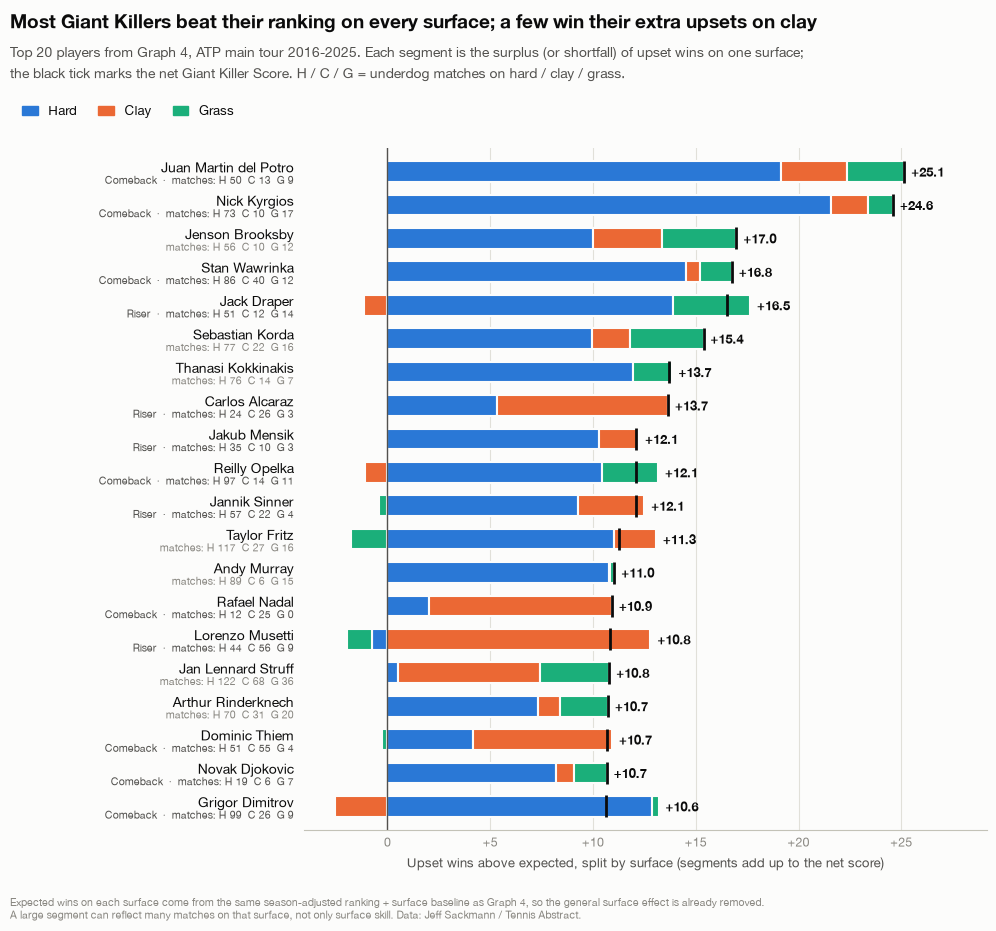

In [13]:
# Diverging stacked bars: positive surface scores stack right of 0, negative ones left; black tick = net score
t = w.iloc[::-1]
fig, ax = plt.subplots(figsize=(10.5, 9.6))
fig.subplots_adjust(left=0.30, right=0.95, top=0.83, bottom=0.12)
ys = np.arange(len(t))
pos_left, neg_left = np.zeros(len(t)), np.zeros(len(t))
for s in SURFACES:
    v = t[f"{s.lower()}_score"].to_numpy()
    ax.barh(ys, v, left=np.where(v >= 0, pos_left, neg_left), height=0.62, color=SURFACE_COLORS[s],
            edgecolor=BG, linewidth=1.5)
    pos_left += np.clip(v, 0, None)
    neg_left += np.clip(v, None, 0)
net = t["gk_score"].to_numpy()
ax.scatter(net, ys, marker="|", s=260, color=INK, linewidths=2, zorder=3)
for yv, right_end, n in zip(ys, pos_left, net):
    ax.annotate(f"{n:+.1f}", xy=(right_end, yv), xytext=(5, 0), textcoords="offset points",
                va="center", fontsize=9.5, fontweight="bold")
for yv, (_, r) in zip(ys, t.iterrows()):
    ax.text(-0.015, yv + 0.13, r["player"], transform=ax.get_yaxis_transform(), ha="right", va="center", fontsize=10)
    mix = "  ".join(f"{s[0]} {int(r[f'{s.lower()}_opportunities'])}" for s in SURFACES)
    tag = "" if r["flag"] == "none" else f"{r['flag'].capitalize()}  ·  "
    ax.text(-0.015, yv - 0.25, f"{tag}matches: {mix}", transform=ax.get_yaxis_transform(), ha="right",
            va="center", fontsize=7.6, color=INK_2 if tag else MUTED)

ax.set_yticks([])
ax.axvline(0, color=INK_2, linewidth=1)
ax.set_xlim(min(0, neg_left.min()) - 1.5, pos_left.max() + 4)
ax.set_ylim(-0.7, len(t) - 0.3)
clean_axis(ax)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:+.0f}" if v else "0"))
ax.set_xlabel("Upset wins above expected, split by surface (segments add up to the net score)", fontsize=9.5)

fig.text(0.02, 0.955, "Most Giant Killers beat their ranking on every surface; a few win their extra upsets on clay",
         fontsize=14, fontweight="bold")
fig.text(0.02, 0.925, "Top 20 players from Graph 4, ATP main tour 2016-2025. Each segment is the surplus (or shortfall) "
         "of upset wins on one surface;", fontsize=10, color=INK_2)
fig.text(0.02, 0.903, "the black tick marks the net Giant Killer Score. H / C / G = underdog matches on "
         "hard / clay / grass.", fontsize=10, color=INK_2)
fig.legend(handles=[Patch(color=SURFACE_COLORS[s], label=s) for s in SURFACES], loc="upper left",
           bbox_to_anchor=(0.02, 0.89), ncol=3, frameon=False, fontsize=9.5, handlelength=1.2, columnspacing=1.6)
fig.text(0.02, 0.025, "Expected wins on each surface come from the same season-adjusted ranking + surface baseline "
         "as Graph 4, so the general surface effect is already removed.\nA large segment can reflect many matches "
         "on that surface, not only surface skill. Data: Jeff Sackmann / Tennis Abstract.",
         fontsize=7.6, color=MUTED, va="bottom")
fig.savefig(FIG / "graph4b_surface_split.png", dpi=200)
fig.savefig(FIG / "graph4b_surface_split.svg")
long.to_csv(DATA / "graph4b_surface_data.csv", index=False)
plt.show()

### Graph 4b findings

- For most of the top 20, surface does **not** explain the score: their extra wins roughly follow where they play
  (del Potro: 76% of his surplus on hard courts, 69% of his matches there). They beat their ranking everywhere.
- A few players are **clay cases**: Musetti (+12.8 on clay, about 0 or below elsewhere), Nadal (+8.9), Alcaraz (+8.3),
  Struff (+6.9 on clay vs +0.5 on hard) and Thiem (+6.8). Kyrgios, Wawrinka and Dimitrov lean toward hard courts.
- **Grass** has too few matches to identify specialists: only 22 players qualify, and the best result is consistent with chance.
- **Ranking changes explain more than surface.** Using only matches with no flag, the surplus mostly vanishes for Wawrinka (16.8 → −1.1),
  Opelka (→ 1.7), Thiem (→ 2.6), Murray (→ 3.2) and Musetti (→ 3.7), but holds up for Brooksby (13.7), Kokkinakis (12.6),
  Kyrgios (12.2), Fritz (10.9) and Rinderknech (10.7).
- The biggest clay over-performers overall are clay specialists outside the top 20 (Djere, Hanfmann, Ruud, Jarry, Garin):
  one ranking blends all surfaces, so clay specialists are underrated on clay.

---
## Overall takeaway

Many upsets aren't really upsets. When a stronger measure such as Elo disagrees with the ranking, or the ranking lags
a comeback or a fast rise, the "underdog" often isn't one. After accounting for that, only a handful of players keep beating
their ranking, and surface explains a few more cases, mostly on clay.